# UTS Data Science
## Klasifikasi Tingkat Risiko Obesitas Berdasarkan Kebiasaan Makan dan Aktivitas Fisik

## 1. Memuat dan Memahami Data

Membaca dataset dan memeriksa ukuran serta tipe data setiap variabel. Pastikan file `Obesity_prediction.csv` berada di folder yang sama dengan notebook.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Periksa lokasi file
file_path = Path("Obesity_prediction.csv")

print("Folder kerja:", Path.cwd())
print("Lokasi dataset:", file_path.resolve())
print("File ditemukan:", file_path.exists())

if not file_path.exists():
    raise FileNotFoundError("File Obesity_prediction.csv tidak ditemukan!")

# Baca dataset
df = pd.read_csv(file_path)

# Periksa dataset
print("Ukuran dataset:", df.shape)
print("\nTipe data setiap kolom:")
print(df.dtypes)

# Tampilkan 5 baris pertama
display(df.head())

## 2. Pemeriksaan Kualitas Data
### 2.1 Missing Value

Menghitung jumlah dan persentase nilai yang hilang pada setiap variabel.

In [ ]:
# Ringkasan missing value
missing_data = pd.DataFrame({
    "Variabel": df.columns,
    "Jumlah": df.isna().sum().values,
})
missing_data["Persentase (%)"] = (
    missing_data["Jumlah"] / len(df) * 100
).round(2)

display(missing_data)

,Variabel,Jumlah,Persentase (%)
0,Gender,0,0.0
1,Age,0,0.0
2,Height,0,0.0
3,Weight,0,0.0
4,family_history,0,0.0
5,FAVC,0,0.0
6,FCVC,0,0.0
7,NCP,0,0.0
8,CAEC,0,0.0
9,SMOKE,0,0.0


### 2.2 Duplikasi Data

Memeriksa jumlah baris duplikat pada dataset.

In [ ]:
# Hitung baris duplikat
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat: {jumlah_duplikat}")

# Distribusi label pada baris yang terduplikasi (jika ada)
if jumlah_duplikat > 0 and "Obesity" in df.columns:
    display(df.loc[df.duplicated(keep=False), "Obesity"].value_counts())

Jumlah baris duplikat: 24


Obesity
Overweight_Level_I     15
Normal_Weight          10
Insufficient_Weight     8
Name: count, dtype: int64

### 2.3 Deteksi Outlier dengan IQR

Metode interquartile range (IQR) digunakan untuk menandai nilai yang berada di luar batas bawah dan batas atas. Penandaan ini perlu ditinjau berdasarkan karakteristik variabel, bukan otomatis dianggap sebagai kesalahan data.

In [ ]:
# Variabel numerik yang diperiksa
kolom_numerik = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]


def outlier_iqr(data, column):
    """Kembalikan jumlah, persentase, dan batas outlier berdasarkan IQR."""
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    mask = (data[column] < batas_bawah) | (data[column] > batas_atas)
    jumlah = int(mask.sum())
    persentase = jumlah / len(data) * 100
    return jumlah, persentase, batas_bawah, batas_atas

hasil_outlier = []
for kolom in kolom_numerik:
    jumlah, persentase, bawah, atas = outlier_iqr(df, kolom)
    hasil_outlier.append([kolom, jumlah, round(persentase, 2), round(bawah, 2), round(atas, 2)])

outlier_df = pd.DataFrame(
    hasil_outlier,
    columns=["Variabel", "Jumlah Outlier", "Persentase (%)", "Batas Bawah", "Batas Atas"],
)
display(outlier_df)

,Variabel,Jumlah Outlier,Persentase (%),Batas Bawah,Batas Atas
0,Age,168,7.96,10.87,35.08
1,Height,1,0.05,1.42,1.98
2,Weight,1,0.05,2.54,170.37
3,FCVC,0,0.00,0.50,4.50
4,NCP,579,27.43,2.15,3.51
5,CH2O,0,0.00,0.25,3.82
6,FAF,0,0.00,-2.19,3.98
7,TUE,0,0.00,-1.50,2.50


#### Visualisasi Boxplot

Boxplot membantu melihat sebaran dan nilai yang terindikasi sebagai outlier.

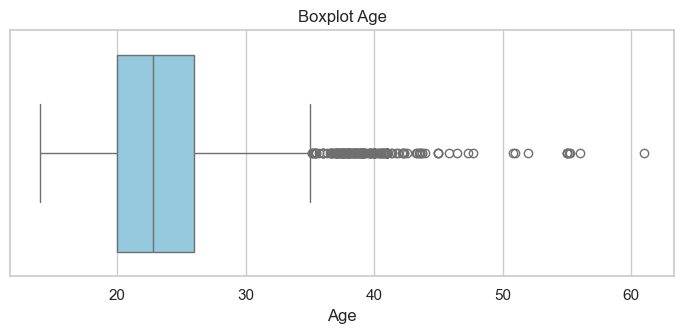

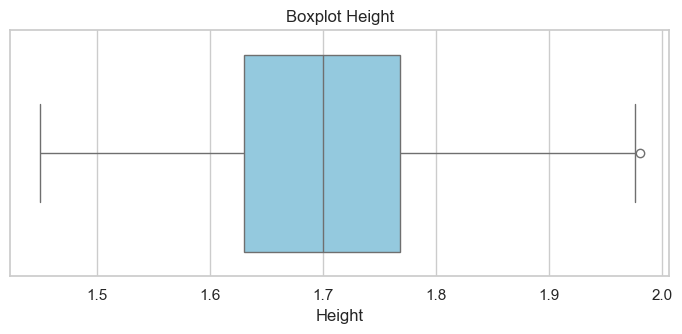

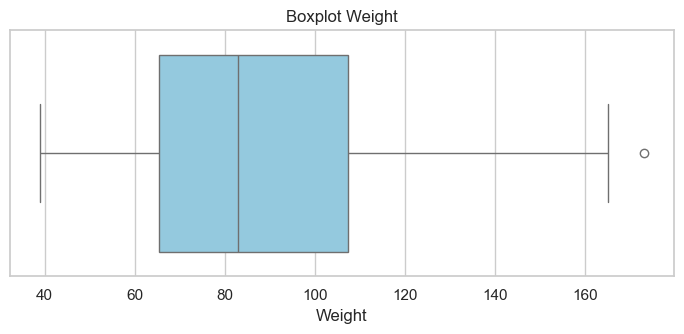

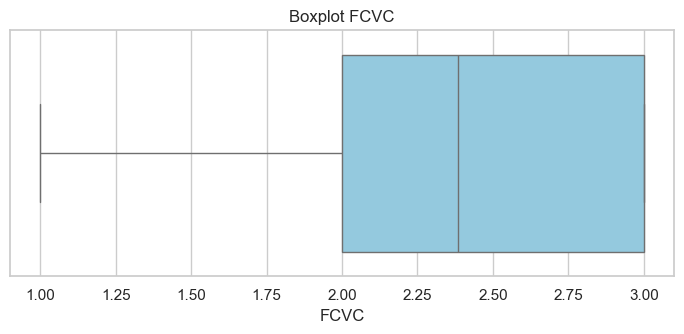

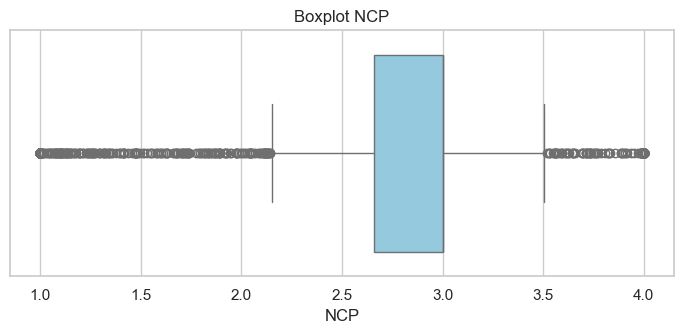

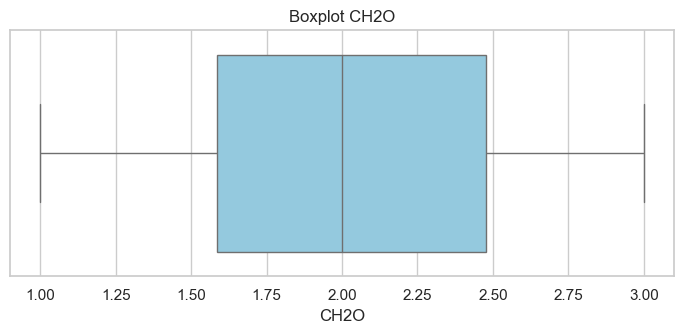

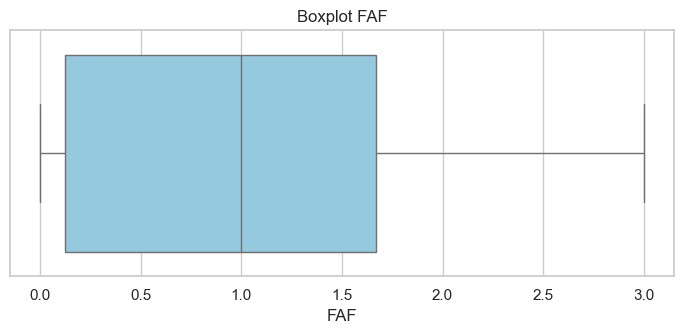

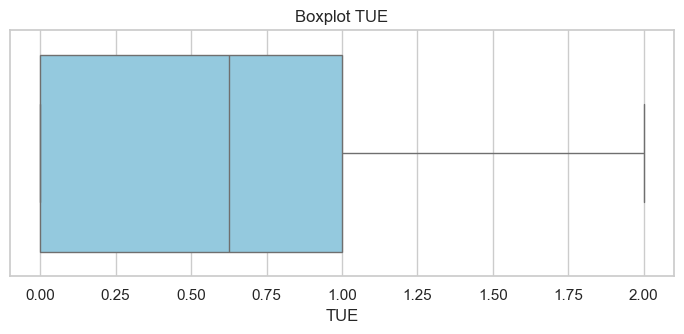

In [ ]:
# Boxplot untuk setiap variabel numerik
for kolom in kolom_numerik:
    plt.figure(figsize=(7, 3.5))
    sns.boxplot(x=df[kolom], color="skyblue")
    plt.title(f"Boxplot {kolom}")
    plt.xlabel(kolom)
    plt.tight_layout()
    plt.show()

**Catatan interpretasi:** outlier pada `Age` perlu dinilai berdasarkan konteks responden. Persentase outlier pada `NCP` dapat dipengaruhi oleh karakteristik variabel diskret dan metode IQR; karena itu, jangan langsung menghapus nilai tersebut tanpa pemeriksaan lebih lanjut.

In [ ]:
# Periksa apakah beberapa fitur ordinal memiliki nilai pecahan.
# Nilai pecahan dapat muncul pada data sintetis atau hasil resampling,
# tetapi pemeriksaan ini saja tidak cukup untuk memastikan asal-usulnya.
kolom_ordinal = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]
for kolom in kolom_ordinal:
    persentase_pecahan = (df[kolom] % 1 != 0).mean() * 100
    print(f"{kolom}: {persentase_pecahan:.1f}% nilai non-bulat")

FCVC: 39.1% nilai non-bulat
NCP: 30.3% nilai non-bulat
CH2O: 61.1% nilai non-bulat
FAF: 57.2% nilai non-bulat
TUE: 54.6% nilai non-bulat


## 3. Exploratory Data Analysis (EDA)
### 3.1 Distribusi Data

Melihat distribusi kelas target, usia, dan berat badan untuk memahami komposisi data.

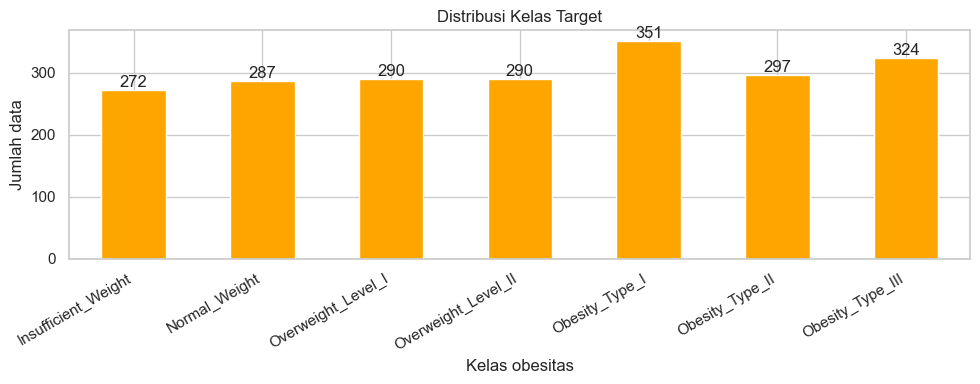

In [ ]:
# Distribusi kelas target
order = [
    "Insufficient_Weight",
    "Normal_Weight",
    "Overweight_Level_I",
    "Overweight_Level_II",
    "Obesity_Type_I",
    "Obesity_Type_II",
    "Obesity_Type_III",
]

jumlah_kelas = df["Obesity"].value_counts().reindex(order, fill_value=0)
ax = jumlah_kelas.plot(kind="bar", figsize=(10, 4), color="orange")
ax.bar_label(ax.containers[0])
ax.set_title("Distribusi Kelas Target")
ax.set_xlabel("Kelas obesitas")
ax.set_ylabel("Jumlah data")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

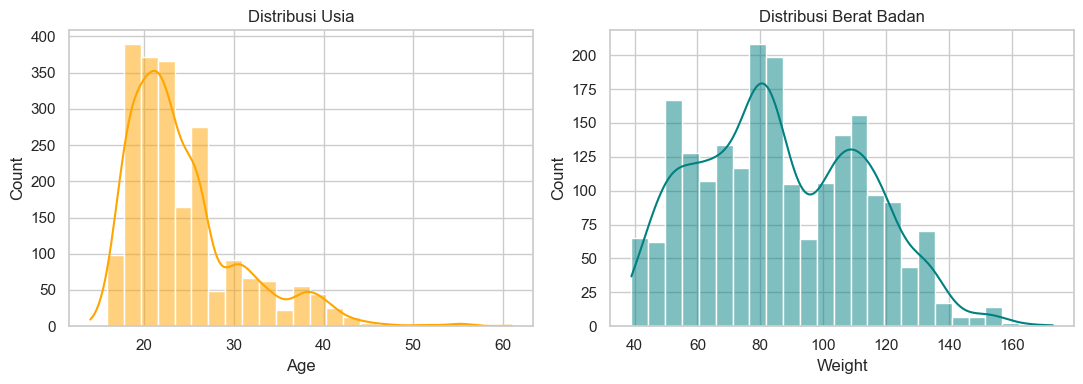

In [ ]:
# Distribusi usia dan berat badan
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x="Age", bins=25, kde=True, ax=axs[0], color="orange")
axs[0].set_title("Distribusi Usia")
sns.histplot(data=df, x="Weight", bins=25, kde=True, ax=axs[1], color="teal")
axs[1].set_title("Distribusi Berat Badan")
plt.tight_layout()
plt.show()

In [ ]:
# Statistik ringkas usia dan berat badan
print(f"Median usia: {df['Age'].median():.1f}")
print(f"Persentase usia ≤ 30 tahun: {(df['Age'] <= 30).mean() * 100:.1f}%")
print(f"Persentase usia > 40 tahun: {(df['Age'] > 40).mean() * 100:.1f}%")
print(
    "Berat badan (kg) — "
    f"minimum: {df['Weight'].min():.1f}, "
    f"maksimum: {df['Weight'].max():.1f}, "
    f"rata-rata: {df['Weight'].mean():.1f}"
)

Median usia: 22.8
Persentase usia ≤ 30 tahun: 83.1%
Persentase usia > 40 tahun: 2.7%
Berat badan (kg) — minimum: 39.0, maksimum: 173.0, rata-rata: 86.6


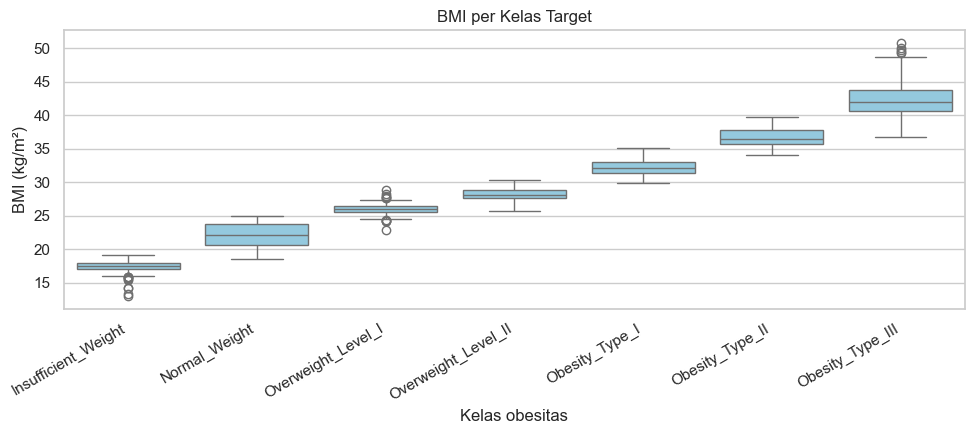

In [ ]:
# Hitung BMI dari berat (kg) dan tinggi (meter)
df["BMI"] = df["Weight"] / (df["Height"] ** 2)

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=df, x="Obesity", y="BMI", order=order, color="skyblue")
plt.title("BMI per Kelas Target")
plt.xlabel("Kelas obesitas")
plt.ylabel("BMI (kg/m²)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Ringkasan BMI per kelas target
display(
    df.groupby("Obesity")["BMI"]
    .agg(Minimum="min", Maksimum="max", Rata_rata="mean")
    .reindex(order)
    .round(2)
)

,Minimum,Maksimum,Rata_rata
Obesity,,,
Insufficient_Weight,13.00,19.08,17.40
Normal_Weight,18.49,24.91,22.01
Overweight_Level_I,22.83,28.77,25.99
Overweight_Level_II,25.71,30.36,28.22
Obesity_Type_I,29.91,35.17,32.26
Obesity_Type_II,34.05,39.79,36.72
Obesity_Type_III,36.77,50.81,42.27


### 3.2 Korelasi Antarvariabel Numerik

Heatmap menunjukkan korelasi antarvariabel numerik. Korelasi tidak dengan sendirinya membuktikan hubungan sebab-akibat.

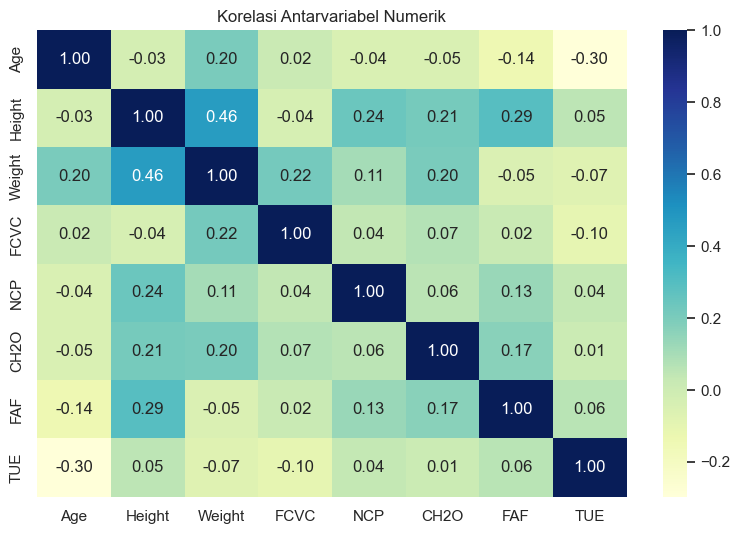

In [ ]:
# Heatmap korelasi fitur numerik
plt.figure(figsize=(8, 5.5))
sns.heatmap(
    df[kolom_numerik].corr(numeric_only=True),
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)

plt.title("Korelasi Antarvariabel Numerik")
plt.tight_layout()
plt.show()

### 3.3 Hubungan Fitur dengan Target

Uji chi-square disertai ukuran asosiasi Cramér’s V digunakan untuk fitur kategorikal. ANOVA digunakan untuk membandingkan rerata fitur numerik antar kelas target. Nilai p perlu ditafsirkan bersama ukuran efek dan asumsi uji.

In [ ]:
from scipy.stats import chi2_contingency, f_oneway

hasil_uji = []
fitur_kategorikal = ["Gender", "family_history", "FAVC", "CAEC", "SMOKE", "SCC", "CALC", "MTRANS"]
fitur_numerik = ["Age", "FCVC", "NCP", "CH2O", "FAF", "TUE"]

# Chi-square untuk fitur kategorikal
for kolom in fitur_kategorikal:
    tabel = pd.crosstab(df[kolom], df["Obesity"])
    chi2, p_value, _, _ = chi2_contingency(tabel)
    denominator = len(df) * (min(tabel.shape) - 1)
    cramers_v = np.sqrt(chi2 / denominator) if denominator > 0 else np.nan
    hasil_uji.append([kolom, "Cramér's V", round(cramers_v, 3), p_value])

# ANOVA satu arah untuk fitur numerik antar kelas target
for kolom in fitur_numerik:
    kelompok = [grup[kolom].dropna().values for _, grup in df.groupby("Obesity")]
    if len(kelompok) > 1 and all(len(g) > 0 for g in kelompok):
        f_stat, p_value = f_oneway(*kelompok)
        hasil_uji.append([kolom, "ANOVA F", round(f_stat, 3), p_value])

hasil_uji_df = pd.DataFrame(
    hasil_uji,
    columns=["Fitur", "Ukuran/Uji", "Nilai", "p-value"],
)
display(hasil_uji_df)

,Fitur,Ukuran/Uji,Nilai,p-value
0,Gender,Cramér's V,0.558,8.088897e-139
1,family_history,Cramér's V,0.543,4.228017e-131
2,FAVC,Cramér's V,0.332,1.482236e-47
3,CAEC,Cramér's V,0.356,7.383853e-159
4,SMOKE,Cramér's V,0.123,1.535424e-05
5,SCC,Cramér's V,0.241,3.773176e-24
6,CALC,Cramér's V,0.231,5.287158e-61
7,MTRANS,Cramér's V,0.186,5.177915e-48
8,Age,ANOVA F,77.954,3.592580e-88
9,FCVC,ANOVA F,112.315,3.732469e-123


In [ ]:
# Persentase nilai "yes" dalam setiap kelas (jika kategori tersebut tersedia)
for kolom in ["family_history", "FAVC"]:
    tabel = pd.crosstab(df[kolom], df["Obesity"], normalize="columns")
    if "yes" in tabel.index:
        print(f"Persentase {kolom} = 'yes' per kelas (%):")
        display((tabel.loc["yes"].reindex(order) * 100).round(1))

# Rata-rata kebiasaan makan dan aktivitas fisik per kelas target
display(df.groupby("Obesity")[kolom_ordinal].mean().reindex(order).round(2))

Persentase family_history = 'yes' per kelas (%):


Obesity
Insufficient_Weight     46.3
Normal_Weight           54.0
Overweight_Level_I      72.1
Overweight_Level_II     93.8
Obesity_Type_I          98.0
Obesity_Type_II         99.7
Obesity_Type_III       100.0
Name: yes, dtype: float64

Persentase FAVC = 'yes' per kelas (%):


Obesity
Insufficient_Weight    81.2
Normal_Weight          72.5
Overweight_Level_I     92.4
Overweight_Level_II    74.5
Obesity_Type_I         96.9
Obesity_Type_II        97.6
Obesity_Type_III       99.7
Name: yes, dtype: float64

,FCVC,NCP,CH2O,FAF,TUE
Obesity,,,,,
Insufficient_Weight,2.48,2.91,1.87,1.25,0.84
Normal_Weight,2.33,2.74,1.85,1.25,0.68
Overweight_Level_I,2.26,2.50,2.06,1.06,0.61
Overweight_Level_II,2.26,2.50,2.03,0.96,0.70
Obesity_Type_I,2.19,2.43,2.11,0.99,0.68
Obesity_Type_II,2.39,2.74,1.88,0.97,0.52
Obesity_Type_III,3.00,3.00,2.21,0.66,0.60


## 4. Representativitas dan Potensi Bias Sampel

Memeriksa komposisi gender pada setiap kelas target serta karakteristik kelas `Obesity_Type_III`. Hasil ini merupakan pemeriksaan awal dan belum cukup untuk menyimpulkan bahwa sampel sepenuhnya representatif.

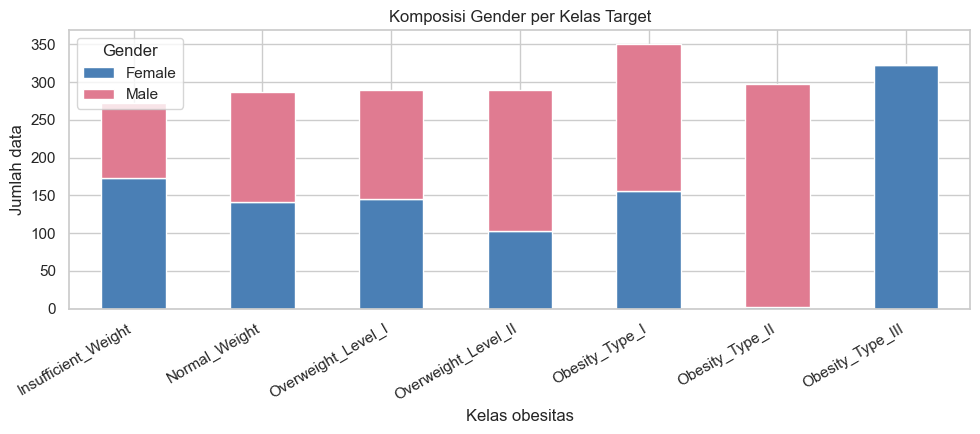

In [ ]:
# Komposisi gender pada setiap kelas target
tabel_gender = pd.crosstab(df["Obesity"], df["Gender"]).reindex(order, fill_value=0)

ax = tabel_gender.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 4.5),
    color=["#4a7fb5", "#e07b91"]
)

ax.set_title("Komposisi Gender per Kelas Target")
ax.set_xlabel("Kelas obesitas")
ax.set_ylabel("Jumlah data")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
# Tabel jumlah data berdasarkan kelas obesitas dan gender
display(pd.crosstab(df["Obesity"], df["Gender"]).reindex(order, fill_value=0))

Gender,Female,Male
Obesity,,
Insufficient_Weight,173,99
Normal_Weight,141,146
Overweight_Level_I,145,145
Overweight_Level_II,103,187
Obesity_Type_I,156,195
Obesity_Type_II,2,295
Obesity_Type_III,323,1


In [ ]:
# Pemeriksaan ringkas karakteristik kelas Obesity_Type_III
t3 = df.loc[df["Obesity"] == "Obesity_Type_III"]

if t3.empty:
    print("Tidak ditemukan data untuk kelas Obesity_Type_III.")
else:
    print(f"Rentang usia: {t3['Age'].min()}–{t3['Age'].max()} tahun")
    for kolom in ["family_history", "MTRANS", "CAEC", "CALC"]:
        print(f"\nDistribusi {kolom}:")
        display(t3[kolom].value_counts(dropna=False).to_frame("Jumlah"))

Rentang usia: 18.0–26.0 tahun

Distribusi family_history:


,Jumlah
family_history,
yes,324



Distribusi MTRANS:


,Jumlah
MTRANS,
Public_Transportation,323
Automobile,1



Distribusi CAEC:


,Jumlah
CAEC,
Sometimes,323
Frequently,1



Distribusi CALC:


,Jumlah
CALC,
Sometimes,323
no,1
